# Etapa 1 — Análise exploratória e diagnóstico do NSL-KDD

**Disciplina:** Inteligência Artificial — Profa. Cristiane Neri Nobre
**Trabalho em competição:** Detecção de Intrusão em Redes (NSL-KDD)
**Equipe:** _preencher_
**Etapa 1 — entrega 24/10/2026**

**Objetivo.** Caracterizar a base KDDTrain+ e produzir um diagnóstico dos dados que orienta a
Etapa 2: identificação das classes, desbalanceamento, atributos categóricos, valores ausentes e
impossíveis, outliers, redundâncias e inconsistências (de atributos e de instâncias) e possíveis
fontes de vazamento de dados (Seção 7 do enunciado).

**Resumo dos resultados**
- 125.973 registros, 41 atributos, **nenhum valor ausente**; única anomalia de domínio:
  `su_attempted` (que deveria ser binário) assume o valor 2 em 59 linhas.
- Desbalanceamento extremo: `normal` 53,5% vs `U2R` 0,04% (razão ≈ 1.295:1). Um classificador
  que responde sempre `normal` tem 53% de acurácia e F1-macro ≈ 0,14.
- `service` tem 70 categorias com cauda longa (15 com < 0,1% dos registros).
- Atributos numéricos fortemente assimétricos (`src_bytes`: mediana 44, máximo ≈ 1,38 bilhão);
  `num_outbound_cmds` é constante; 10 pares de atributos com |r| > 0,95.
- "Outliers" concentram ataques: eliminá-los por regra cega apagaria justamente as classes raras.
- 31 registros (15 grupos) repetem os 41 atributos com rótulos de ataque diferentes
  (inconsistentes); não há duplicatas exatas com o mesmo rótulo.
- `difficulty` é metadado do processo de rotulagem → vazamento, será descartado. Nenhum dos 41
  atributos se comporta como substituto do rótulo.
- O teste tem 17 ataques inéditos e muito mais R2L/U2R: a validação cruzada no treino será otimista.

**Índice**
0. Configuração e política de dados
1. Carga e visão geral
2. Valores ausentes e valores impossíveis
3. Classe-alvo e desbalanceamento
4. Atributos categóricos
5. Atributos numéricos
6. Outliers
7. Redundância de atributos
8. Redundância e inconsistência de instâncias
9. Investigação de vazamento de dados
10. Comparação descritiva treino × teste (somente rótulos)
11. Diagnóstico e plano para a Etapa 2

## 0. Configuração e política de dados

Bibliotecas, semente global (`config.RANDOM_STATE = 42`) e estilo dos gráficos. As cores das
cinco classes são fixas em todo o notebook (a mesma classe tem sempre a mesma cor).

In [1]:
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, imblearn
from IPython.display import display
from nslkdd import config, load_train_frame
from nslkdd.audit import association_with_target

np.random.seed(config.RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES.mkdir(parents=True, exist_ok=True)

CLASSES = config.CLASSES
PALETTE = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))


def savefig(fig, name):
    """Salva a figura em results/figures/eda_<name>.png (usada no relatório)."""
    fig.savefig(config.FIGURES / f"eda_{name}.png", dpi=150, bbox_inches="tight")


print({m.__name__: m.__version__ for m in (np, pd, sklearn, imblearn, sns)})
print("RANDOM_STATE =", config.RANDOM_STATE)

{'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'imblearn': '0.14.2', 'seaborn': '0.13.2'}
RANDOM_STATE = 42


**Política de dados.** Toda a análise e toda decisão desta etapa usam **apenas o KDDTrain+**.
O KDDTest+ é reservado à avaliação final (notebook 04). A única exceção, na Seção 10, é uma
comparação *descritiva* da distribuição dos **rótulos** do teste (classe e nome do ataque),
sem olhar nenhum atributo do teste e sem que ela altere qualquer decisão de pré-processamento:
serve apenas para documentar a mudança de distribuição prevista na literatura (Tavallaee et
al., 2009) e calibrar a expectativa sobre a validação cruzada.

## 1. Carga e visão geral

A leitura usa o carregador do pacote do projeto, que aplica os nomes das 43 colunas
(41 atributos + `attack` + `difficulty`) e cria `category`, o mapeamento do nome do ataque para
as 5 classes do problema (`normal`, `DoS`, `Probe`, `R2L`, `U2R`).

In [2]:
df = load_train_frame()
X = df[config.FEATURES]
print("shape:", df.shape)
print(f"memória: {df.memory_usage(deep=True).sum() / 2**20:.1f} MiB")
df.head()

shape: (125973, 44)
memória: 69.5 MiB


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,difficulty,category
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,DoS
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,normal


Classificamos cada atributo pelo tipo semântico (não só pelo `dtype`), pois isso define o
tratamento na Etapa 2: categóricos precisam de conversão simbólico-numérica, taxas já estão em
[0, 1], contagens/volumes têm cauda longa.

In [3]:
def kind_of(col):
    if col in config.CATEGORICAL:
        return "categórico"
    if col in config.BINARY or col == "su_attempted":
        return "binário"
    if col.endswith("rate"):
        return "taxa [0,1]"
    return "contagem/contínuo"


types = pd.DataFrame({
    "dtype": X.dtypes.astype(str),
    "tipo": [kind_of(c) for c in X.columns],
    "n_valores": X.nunique(),
})
print(types["tipo"].value_counts().to_string())
types.T

tipo
contagem/contínuo    17
taxa [0,1]           15
binário               6
categórico            3


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
dtype,int64,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64
tipo,contagem/contínuo,categórico,categórico,categórico,contagem/contínuo,contagem/contínuo,binário,contagem/contínuo,contagem/contínuo,contagem/contínuo,contagem/contínuo,binário,contagem/contínuo,binário,binário,contagem/contínuo,contagem/contínuo,contagem/contínuo,contagem/contínuo,contagem/contínuo,binário,binário,contagem/contínuo,contagem/contínuo,"taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]",contagem/contínuo,contagem/contínuo,"taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]","taxa [0,1]"
n_valores,2981,3,70,11,3341,9326,2,3,4,28,6,2,88,2,3,82,35,3,10,1,2,2,512,509,89,86,82,62,101,95,60,256,256,101,101,101,75,101,100,101,101


São 3 atributos categóricos (`protocol_type`, `service`, `flag`), 6 binários (incluindo
`su_attempted`, que pela documentação deveria ser binário), 15 taxas e 17 contagens/volumes
contínuos. Além deles, `attack` (rótulo original) e `difficulty` (metadado, ver Seção 9).

## 2. Valores ausentes e valores impossíveis

Além de procurar `NaN`, verificamos valores fora do domínio: taxas fora de [0, 1], contagens
negativas e atributos binários com mais de dois valores.

In [4]:
print("valores ausentes no total:", int(df.isna().sum().sum()))

rates = [c for c in config.NUMERIC if c.endswith("rate")]
checks = {
    "taxas fora de [0,1]": int(((X[rates] < 0) | (X[rates] > 1)).sum().sum()),
    "valores negativos (numéricos)": int((X[config.NUMERIC] < 0).sum().sum()),
    "binários com > 2 valores": [c for c in config.BINARY if X[c].nunique() > 2],
}
print(checks)
print("\nsu_attempted:", X["su_attempted"].value_counts().sort_index().to_dict())
pd.crosstab(df["su_attempted"], df["category"])

valores ausentes no total: 0
{'taxas fora de [0,1]': 0, 'valores negativos (numéricos)': 0, 'binários com > 2 valores': []}

su_attempted: {0: 125893, 1: 21, 2: 59}


category,DoS,Probe,R2L,U2R,normal
su_attempted,,,,,
0,45927,11656,994,52,67264
1,0,0,1,0,20
2,0,0,0,0,59


A base **não tem valores ausentes** e nenhuma taxa ou contagem está fora do domínio, portanto
a etapa de tratamento de dados ausentes não se aplica (registramos a verificação para o
relatório). A única inconsistência de domínio é `su_attempted`: documentado como binário
("1 se houve tentativa de `su root`"), assume o valor **2 em 59 registros**. Como 2 > 0 também
indica tentativa, a interpretação mais natural é tratá-lo como contagem (ou binarizá-lo como
`> 0`); ambas as opções preservam a informação e serão decididas na Etapa 2.

## 3. Classe-alvo e desbalanceamento

,n,%,razão normal:classe
category,,,
normal,67343,53.46,1
DoS,45927,36.46,1
Probe,11656,9.25,6
R2L,995,0.79,68
U2R,52,0.04,1295


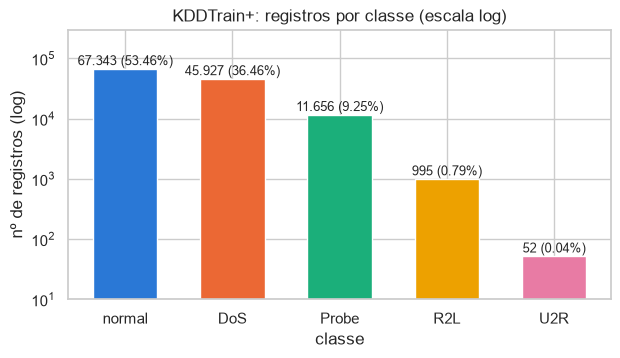

In [5]:
cls = pd.DataFrame({"n": df["category"].value_counts().reindex(CLASSES)})
cls["%"] = (100 * cls["n"] / cls["n"].sum()).round(2)
cls["razão normal:classe"] = (cls.loc["normal", "n"] / cls["n"]).round(0).astype(int)
display(cls)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(cls.index, cls["n"], color=[PALETTE[c] for c in cls.index], width=0.6)
ax.set_yscale("log")
for i, (n, p) in enumerate(zip(cls["n"], cls["%"])):
    ax.text(i, n * 1.15, f"{n:,} ({p}%)".replace(",", "."), ha="center", fontsize=9)
ax.set(title="KDDTrain+: registros por classe (escala log)", xlabel="classe",
       ylabel="nº de registros (log)", ylim=(10, 3e5))
savefig(fig, "classes")
plt.show()

O desbalanceamento é extremo: `U2R` tem **52 registros (0,04%)**, cerca de **1.295 vezes menos**
que `normal`, e `R2L` tem 995 (0,8%). A escala log é necessária para que as classes raras sequer
apareçam no gráfico.

**Por que acurácia engana.** O classificador trivial que responde sempre `normal` acerta 53,5%
dos registros, mas o seu F1-macro é muito baixo, porque o F1 das outras quatro classes é zero:

In [6]:
from sklearn.metrics import accuracy_score, f1_score

y = df["category"]
trivial = np.full(len(y), "normal")
print(f"acurácia = {accuracy_score(y, trivial):.3f}   "
      f"F1-macro = {f1_score(y, trivial, average='macro', labels=CLASSES, zero_division=0):.3f}")

acurácia = 0.535   F1-macro = 0.139


Daí a métrica oficial ser o **F1-macro**, que dá o mesmo peso às cinco classes: errar todo o
`U2R` custa tanto quanto errar todo o `normal`. Por isso a Etapa 2 precisa comparar técnicas de
**balanceamento** (sobreamostragem, subamostragem, híbridas e pesos de classe).

Dentro de cada classe, os nomes de ataque também são desbalanceados:

In [7]:
atk = (df.groupby(["category", "attack"]).size().rename("n").reset_index()
         .sort_values(["category", "n"], ascending=[True, False]))
atk["% da classe"] = (100 * atk["n"] / atk.groupby("category")["n"].transform("sum")).round(1)
atk.set_index(["category", "attack"]).loc[CLASSES[1:]]

n  % da classe
category attack                             
DoS      neptune          41214         89.7
         smurf             2646          5.8
         back               956          2.1
         teardrop           892          1.9
         pod                201          0.4
         land                18          0.0
Probe    satan             3633         31.2
         ipsweep           3599         30.9
         portsweep         2931         25.1
         nmap              1493         12.8
R2L      warezclient        890         89.4
         guess_passwd        53          5.3
         warezmaster         20          2.0
         imap                11          1.1
         ftp_write            8          0.8
         multihop             7          0.7
         phf                  4          0.4
         spy                  2          0.2
U2R      buffer_overflow     30         57.7
         rootkit             10         19.2
         loadmodule           9         17.3
         perl                 3          5.8

Cada classe é dominada por um ou dois ataques: `neptune` é 90% do `DoS`, `warezclient` é 89% do
`R2L` e `U2R` tem apenas 4 ataques, com `buffer_overflow` representando 58%. Para `R2L` e `U2R`
o modelo aprende essencialmente um ou dois padrões, o que é um risco para generalização
(retomado na Seção 10).

## 4. Atributos categóricos

protocol_type     3
service          70
flag             11


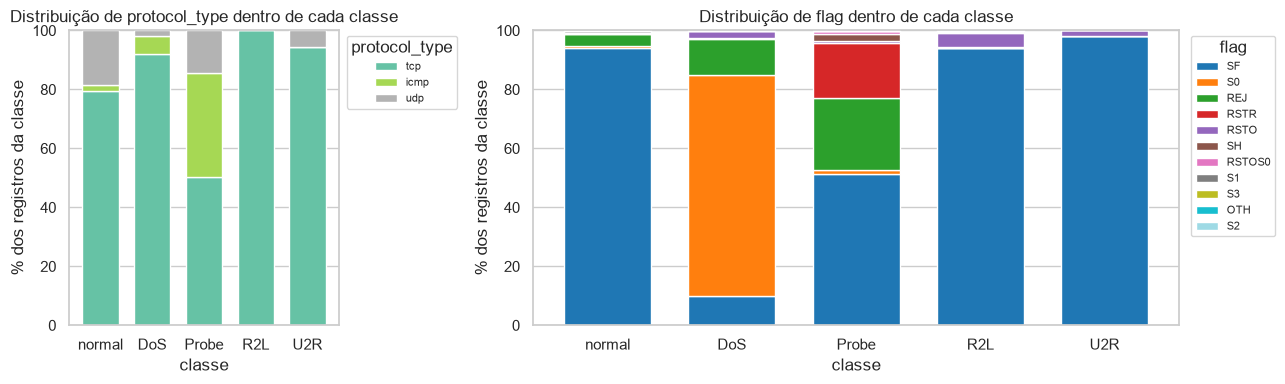

In [8]:
print(X[config.CATEGORICAL].nunique().to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2.4]})
for ax, col in zip(axes, ["protocol_type", "flag"]):
    ct = pd.crosstab(df[col], df["category"], normalize="columns")[CLASSES] * 100
    ct = ct.loc[ct.max(axis=1).sort_values(ascending=False).index]
    ct.T.plot.bar(stacked=True, ax=ax, colormap="tab20" if col == "flag" else "Set2",
                  width=0.7, edgecolor="white", linewidth=1)
    ax.set(title=f"Distribuição de {col} dentro de cada classe", xlabel="classe",
           ylabel="% dos registros da classe")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title=col, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
savefig(fig, "protocol_flag")
plt.show()

`protocol_type` e `flag` são bastante discriminantes: `R2L` e `U2R` são quase só TCP e, como
`normal` (80% TCP), quase só conexões completadas normalmente (`SF`), enquanto `DoS` concentra conexões com erro de SYN
(`S0`, assinatura do `neptune`) e `Probe` concentra `REJ`/`RSTR`/`SH` e ICMP (varreduras).
Com 3 e 11 categorias, a codificação *one-hot* é adequada para ambos.

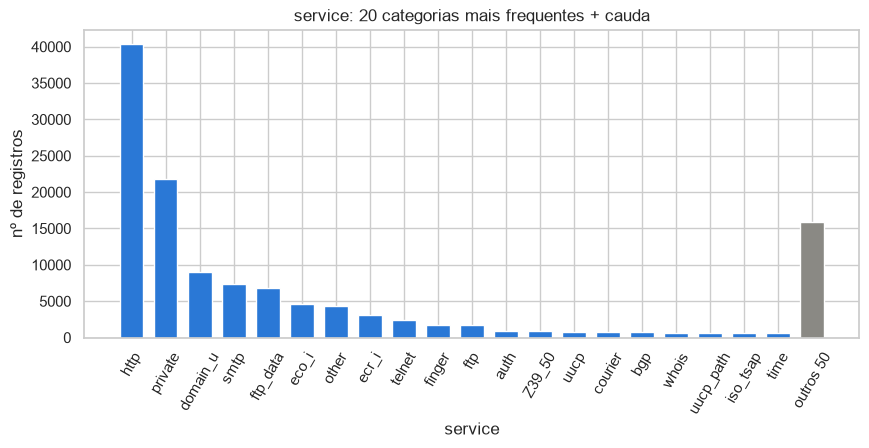

70 categorias; top-20 cobrem 87.4% dos registros; 15 categorias com < 0,1% (490 registros)
raras: rje (86), remote_job (78), pop_2 (78), X11 (73), printer (69), shell (65), urh_i (10), tim_i (8), red_i (8), pm_dump (5), tftp_u (3), http_8001 (2), aol (2), harvest (2), http_2784 (1)


In [9]:
svc = df["service"].value_counts()
top = svc.head(20)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(top.index, top.values, color="#2a78d6", width=0.7)
ax.bar("outros 50", svc.iloc[20:].sum(), color="#8a8984", width=0.7)
ax.set(title="service: 20 categorias mais frequentes + cauda", xlabel="service",
       ylabel="nº de registros")
ax.tick_params(axis="x", rotation=60)
savefig(fig, "service_top20")
plt.show()

freq = svc / len(df)
rare = freq[freq < 0.001]
print(f"{len(svc)} categorias; top-20 cobrem {100 * top.sum() / len(df):.1f}% dos registros; "
      f"{len(rare)} categorias com < 0,1% ({rare.sum() * len(df):.0f} registros)")
print("raras:", ", ".join(f"{s} ({svc[s]})" for s in rare.index))

Qual a relação entre `service` e as classes raras? A tabela mostra os serviços mais
frequentes dentro de `R2L` e `U2R`:

In [10]:
for c in ["R2L", "U2R"]:
    s = df.loc[df["category"] == c, "service"].value_counts()
    print(f"{c}: {s.head(6).to_dict()}  ({s.size} serviços distintos)")

R2L: {'ftp_data': 604, 'ftp': 312, 'telnet': 57, 'imap4': 11, 'other': 5, 'http': 4}  (7 serviços distintos)
U2R: {'telnet': 34, 'ftp_data': 12, 'ftp': 3, 'other': 3}  (4 serviços distintos)


**Alta cardinalidade de `service`.** São 70 categorias com cauda longa: as 20 mais frequentes
cobrem quase todos os registros e 15 categorias aparecem em menos de 0,1% das linhas (algumas
com 1 ou 2 ocorrências). As opções de conversão simbólico-numérica e seus efeitos:

- **One-hot** (69–70 colunas binárias, esparsas): não impõe ordem inexistente, mas quase dobra a
  dimensionalidade, prejudica métodos baseados em distância (KNN) e cria colunas quase vazias que
  não generalizam. **Agrupar as categorias raras** em `outros` antes do one-hot reduz esse efeito.
- **Codificação por frequência** (1 coluna): compacta, mas serviços diferentes com frequência
  parecida colapsam no mesmo valor.
- **Target encoding** (1 coluna por classe): muito informativo, porém usa o rótulo e por isso
  **precisa ser ajustado só nos folds de treino** (dentro do pipeline), senão vaza informação.
- Codificação ordinal (inteiros arbitrários) impõe uma ordem que não existe; serve apenas para
  árvores.

Os serviços são decisivos para as classes raras (`R2L` concentra-se em `ftp_data`/`ftp`;
`U2R` em `telnet`/`ftp_data`), logo a codificação escolhida não pode apagar essas categorias.
As alternativas serão comparadas por validação cruzada na Etapa 2.

## 5. Atributos numéricos

Resumo estatístico, assimetria (*skewness*) e fração de zeros de cada atributo numérico.

In [11]:
num = X[config.NUMERIC]
summary = num.describe().T[["mean", "std", "min", "50%", "max"]]
summary["skew"] = num.skew()
summary["% zeros"] = 100 * (num == 0).mean()
summary["n_valores"] = num.nunique()
summary.sort_values("skew", ascending=False).round(3)

,mean,std,min,50%,max,skew,% zeros,n_valores
is_host_login,0.000,0.003,0.0,0.00,1.000000e+00,354.927,99.999,2
dst_bytes,19779.114,4021269.151,0.0,0.00,1.309937e+09,290.053,53.954,9326
num_compromised,0.279,23.942,0.0,0.00,7.479000e+03,250.108,98.979,88
num_root,0.302,24.400,0.0,0.00,7.468000e+03,236.914,99.485,82
src_bytes,45566.743,5870331.182,0.0,44.00,1.379964e+09,190.669,39.208,3341
urgent,0.000,0.014,0.0,0.00,3.000000e+00,149.915,99.993,4
land,0.000,0.014,0.0,0.00,1.000000e+00,70.965,99.980,2
num_shells,0.000,0.022,0.0,0.00,2.000000e+00,59.592,99.963,3
num_file_creations,0.013,0.484,0.0,0.00,4.300000e+01,55.665,99.772,35
num_failed_logins,0.001,0.045,0.0,0.00,5.000000e+00,53.764,99.903,6


Quase todos os atributos de conteúdo (`hot`, `num_*`, `root_shell`...) são zero em mais de 97%
dos registros, e as contagens/volumes têm assimetria enorme (`dst_bytes`, `src_bytes`,
`num_compromised`, `num_root` com skew > 190). Observações:

- **`num_outbound_cmds` é constante (sempre 0)**: não carrega informação → remover.
- **Quase constantes:** `is_host_login` (1 registro com valor 1), `land` (25), `urgent`
  (≈ 0,007% não nulos). Não são constantes de fato, então só serão removidos se a seleção de
  atributos da Etapa 2 indicar.
- As escalas são muito diferentes (taxas em [0, 1] contra bytes na casa dos bilhões), o que afeta
  KNN, MLP e qualquer método baseado em distância ou gradiente → normalização é obrigatória para
  esses modelos.

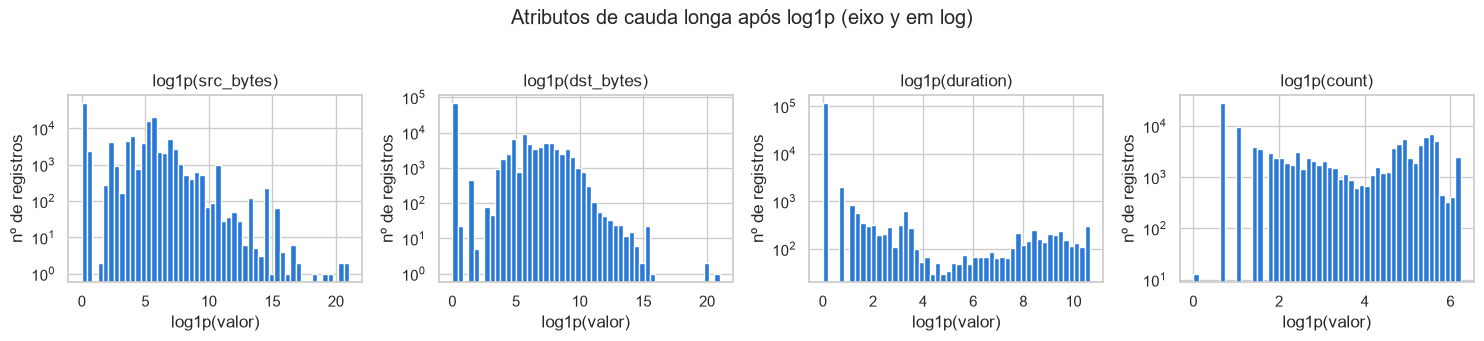

        src_bytes     dst_bytes  duration  count
50%  4.400000e+01  0.000000e+00       0.0   14.0
max  1.379964e+09  1.309937e+09   42908.0  511.0


In [12]:
heavy = ["src_bytes", "dst_bytes", "duration", "count"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, col in zip(axes, heavy):
    ax.hist(np.log1p(df[col]), bins=50, color="#2a78d6")
    ax.set(title=f"log1p({col})", xlabel="log1p(valor)", ylabel="nº de registros")
    ax.set_yscale("log")
fig.suptitle("Atributos de cauda longa após log1p (eixo y em log)", y=1.03)
fig.tight_layout()
savefig(fig, "log_hist")
plt.show()
print(df[heavy].describe().loc[["50%", "max"]].to_string())

Mesmo em escala log as distribuições são multimodais e com massa em zero (`duration` é 0 em
mais de 90% dos registros). `src_bytes` tem mediana 44 e máximo ≈ 1,38 × 10⁹. Uma
**transformação `log1p` antes da normalização** comprime a cauda sem perder a ordem dos valores;
sem ela, um `StandardScaler` ou `MinMaxScaler` seria dominado por poucos valores extremos.

A seguir, os 8 atributos numéricos com maior associação com a classe (razão de correlação *eta*,
calculada no treino; ver Seção 9) e sua distribuição por classe.

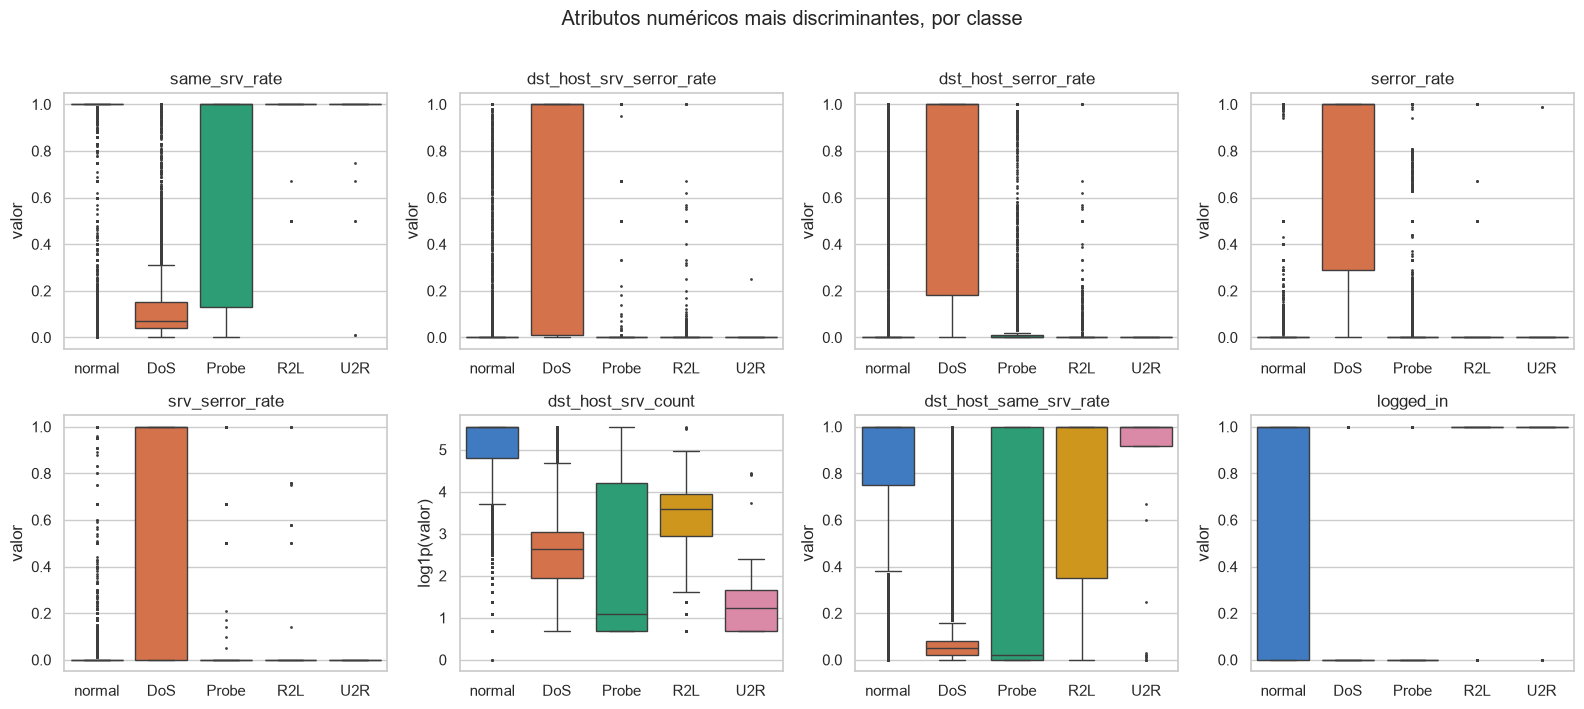

In [13]:
assoc_num = association_with_target(num.drop(columns=config.CONSTANT_IN_TRAIN), y)
top8 = assoc_num["atributo"].head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), top8):
    vals = np.log1p(df[col]) if col in config.HEAVY_TAILED else df[col]
    sns.boxplot(x=df["category"], y=vals, order=CLASSES, palette=PALETTE, ax=ax,
                fliersize=1, linewidth=1)
    ax.set(title=col, xlabel="", ylabel="log1p(valor)" if col in config.HEAVY_TAILED else "valor")
fig.suptitle("Atributos numéricos mais discriminantes, por classe", y=1.01)
fig.tight_layout()
savefig(fig, "boxplots_classe")
plt.show()

Os atributos de tráfego (taxas de erro SYN, `same_srv_rate`, `count`, `dst_host_*`) separam
muito bem `DoS` e `Probe` de `normal`, pois esses ataques geram muitas conexões em pouco tempo.
Já `R2L` e `U2R` ficam iguais a `normal` nas taxas de erro e em `same_srv_rate`; só
`logged_in` (sempre 1 nessas classes) e `dst_host_srv_count` (menor em `U2R`) ajudam um pouco.
São ataques de **uma única conexão**, cujo sinal está nos atributos de conteúdo (`hot`, `num_failed_logins`,
`root_shell`, `num_file_creations`...) e em `service`/`duration`/bytes. Essa é a principal
dificuldade do problema: as classes raras são justamente as menos separáveis.

## 6. Outliers

Aplicamos a regra do intervalo interquartil (IQR, 1,5 × IQR) e o z-score (|z| > 3) **em escala
`log1p`** aos atributos de cauda longa e medimos, entre os registros marcados como outlier,
a proporção de cada classe. A pergunta é: eliminar outliers por regra automática é seguro aqui?

In [14]:
logged = np.log1p(df[config.HEAVY_TAILED])
q1, q3 = logged.quantile(0.25), logged.quantile(0.75)
iqr = q3 - q1
iqr_out = ((logged < q1 - 1.5 * iqr) | (logged > q3 + 1.5 * iqr)).any(axis=1)
z = (logged - logged.mean()) / logged.std()
z_out = (z.abs() > 3).any(axis=1)

rows = {}
for name, mask in [("IQR (log1p)", iqr_out), ("|z| > 3 (log1p)", z_out)]:
    frac = mask.groupby(df["category"]).mean().reindex(CLASSES) * 100
    rows[name] = frac
    print(f"{name}: {mask.sum():,} registros ({100 * mask.mean():.1f}%) marcados".replace(",", "."))
out_tab = pd.DataFrame(rows).round(1)
out_tab.index.name = "% da classe marcada como outlier"
out_tab

IQR (log1p): 27.617 registros (21.9%) marcados
|z| > 3 (log1p): 11.613 registros (9.2%) marcados


,IQR (log1p),|z| > 3 (log1p)
% da classe marcada como outlier,,
normal,26.4,8.6
DoS,6.6,5.2
Probe,49.8,24.8
R2L,95.8,52.7
U2R,98.1,76.9


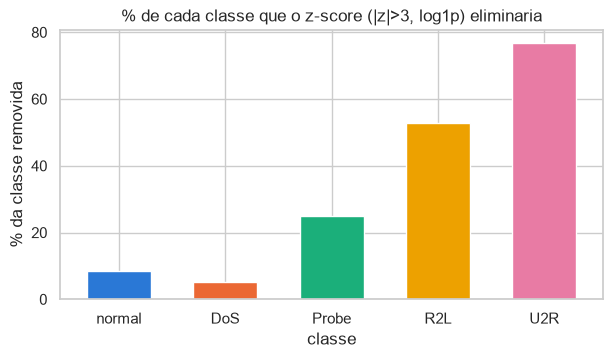

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
out_tab["|z| > 3 (log1p)"].plot.bar(ax=ax, color=[PALETTE[c] for c in CLASSES], width=0.6)
ax.set(title="% de cada classe que o z-score (|z|>3, log1p) eliminaria", xlabel="classe",
       ylabel="% da classe removida")
ax.tick_params(axis="x", rotation=0)
savefig(fig, "outliers_classe")
plt.show()

Os registros "atípicos" **não são ruído**: o z-score eliminaria 53% do `R2L` e 77% do `U2R`
(o IQR, 96% e 98%), contra 9% do `normal`, porque o que diferencia esses ataques é exatamente ter
valores raros em `duration`, bytes, `hot`, `num_file_creations` etc. Remover outliers por uma
regra cega apagaria uma parte grande das classes que mais pesam no F1-macro. Conclusão: **não
eliminar outliers globalmente**; a cauda longa será tratada por transformação (`log1p`) e
normalização robusta. Se alguma remoção for testada na Etapa 2, deverá ser feita por classe,
dentro do pipeline, e só sobre a classe majoritária.

## 7. Redundância de atributos

Pelo material da disciplina, um atributo é redundante quando seu valor pode ser deduzido de
outro(s), o que se manifesta como correlação alta. Calculamos Pearson (linear) e Spearman
(monotônica, robusta à cauda longa) entre os 37 atributos numéricos não constantes.

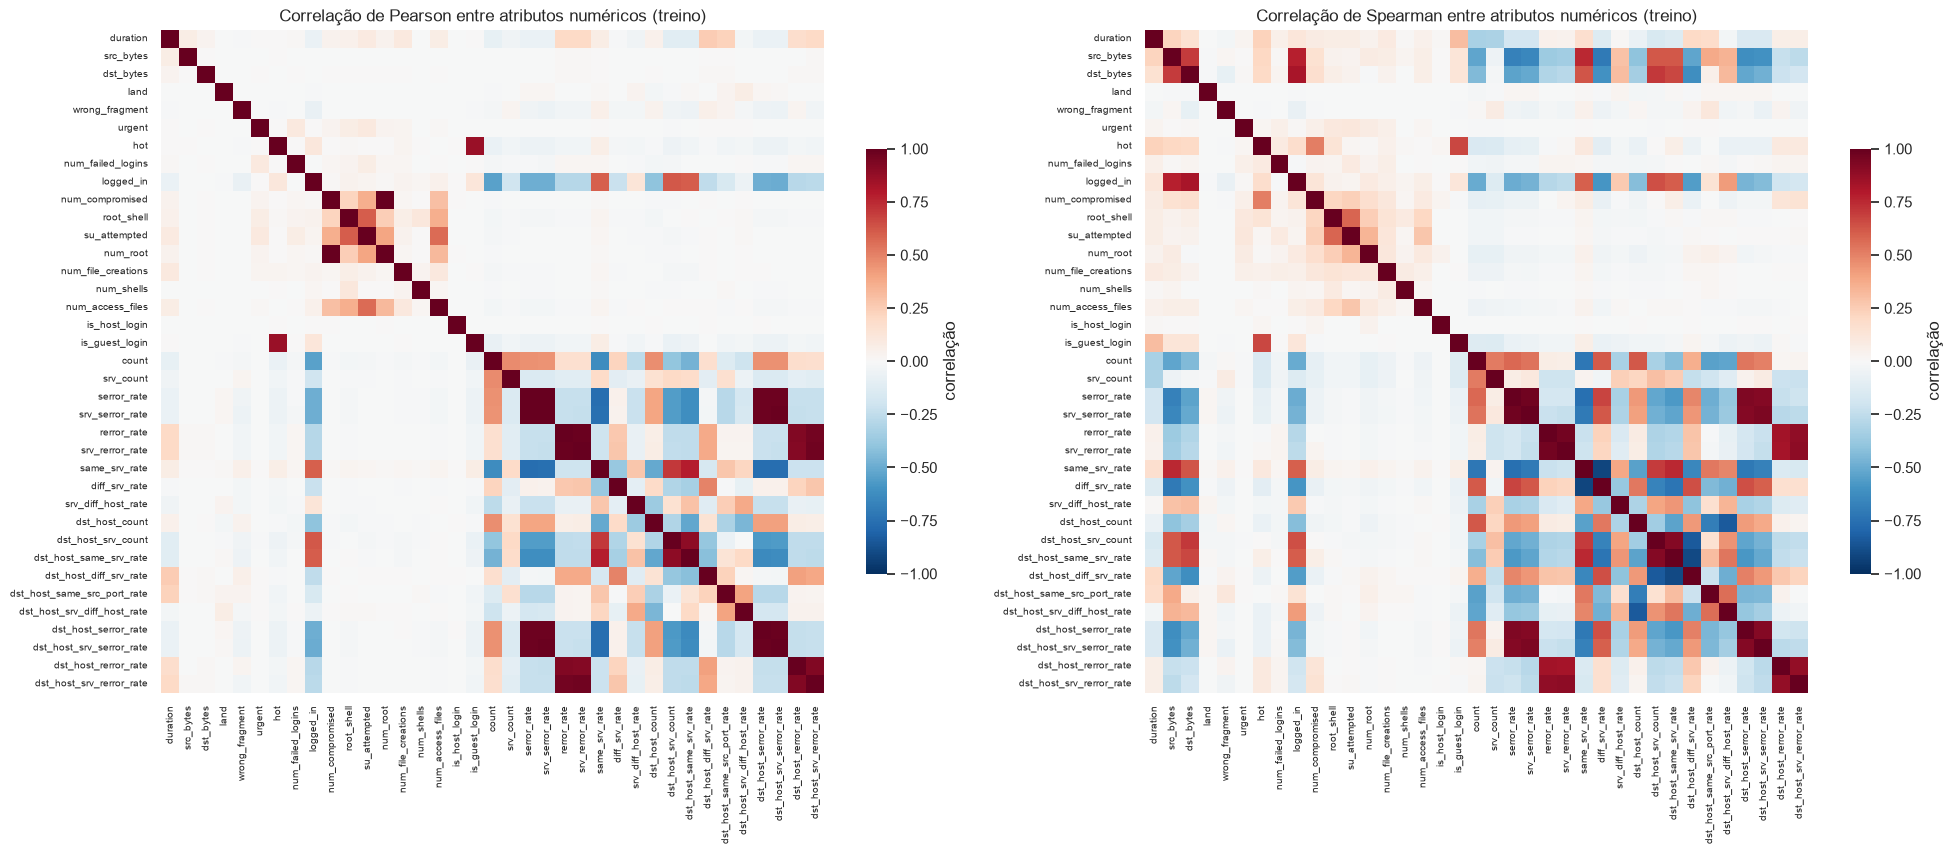

In [16]:
num_nc = num.drop(columns=config.CONSTANT_IN_TRAIN)
pearson = num_nc.corr(method="pearson")
spearman = num_nc.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, (name, m) in zip(axes, [("Pearson", pearson), ("Spearman", spearman)]):
    sns.heatmap(m, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, ax=ax,
                cbar_kws={"shrink": 0.6, "label": "correlação"}, xticklabels=True, yticklabels=True)
    ax.set_title(f"Correlação de {name} entre atributos numéricos (treino)")
    ax.tick_params(labelsize=7)
fig.tight_layout()
savefig(fig, "correlacao")
plt.show()

In [17]:
def high_pairs(m, thr=0.95):
    upper = m.where(np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
    return upper[upper.abs() > thr].sort_values(ascending=False)


hp = pd.DataFrame({"pearson": high_pairs(pearson)})
hp["spearman"] = [spearman.loc[a, b] for a, b in hp.index]
print(f"{len(hp)} pares com |Pearson| > 0,95; "
      f"{len(high_pairs(spearman))} pares com |Spearman| > 0,95")
hp.round(3)

10 pares com |Pearson| > 0,95; 2 pares com |Spearman| > 0,95


pearson  spearman
num_compromised      num_root                    0.999     0.165
serror_rate          srv_serror_rate             0.993     0.973
rerror_rate          srv_rerror_rate             0.989     0.966
srv_serror_rate      dst_host_srv_serror_rate    0.986     0.942
dst_host_serror_rate dst_host_srv_serror_rate    0.985     0.919
serror_rate          dst_host_srv_serror_rate    0.981     0.922
                     dst_host_serror_rate        0.979     0.936
srv_serror_rate      dst_host_serror_rate        0.978     0.919
srv_rerror_rate      dst_host_srv_rerror_rate    0.970     0.894
rerror_rate          dst_host_srv_rerror_rate    0.964     0.884

Há **10 pares com |r| > 0,95**, formando três grupos:
- `num_compromised` ~ `num_root` (r ≈ 0,999): praticamente o mesmo atributo;
- grupo de erro SYN: `serror_rate`, `srv_serror_rate`, `dst_host_serror_rate`,
  `dst_host_srv_serror_rate`;
- grupo de erro REJ: `rerror_rate`, `srv_rerror_rate`, `dst_host_srv_rerror_rate`.

Pelo Spearman, apenas 2 pares passam de 0,95 e `num_compromised` ~ `num_root` cai para 0,17:
a correlação de Pearson desse par vem de poucos valores extremos (quase todos os registros
são zero em ambos). Ou seja, a redundância "forte" do grupo de conteúdo é menor do que parece,
enquanto a dos grupos de taxas de erro se confirma pelas duas medidas.

São atributos redundantes: medem o mesmo fenômeno em janelas diferentes (2 s vs. últimas 100
conexões para o mesmo host). Árvores e florestas são pouco afetadas, mas KNN (distância conta o
mesmo fenômeno várias vezes) e Naive Bayes (supõe independência) sofrem. Na Etapa 2, isso
motiva testar **seleção de atributos** ou **PCA** (redução de dimensionalidade), sempre ajustados
dentro do pipeline.

## 8. Redundância e inconsistência de instâncias

Segundo o material, uma instância é **redundante** quando é igual (ou muito semelhante) a outra,
e o conjunto é **inconsistente** quando há "duas instâncias iguais com classificações
diferentes". Verificamos ambos considerando os 41 atributos (sem `difficulty`, que é metadado).

In [18]:
dup_feat = X.duplicated(keep=False)
report = {
    "linhas idênticas (todas as colunas, com difficulty)": int(df.duplicated().sum()),
    "linhas idênticas (41 atributos + attack)": int(df[config.FEATURES + ["attack"]].duplicated().sum()),
    "linhas com os 41 atributos repetidos (cópias excedentes)": int(X.duplicated().sum()),
    "linhas envolvidas em algum grupo repetido": int(dup_feat.sum()),
}
groups = df[dup_feat].groupby(config.FEATURES, sort=False)
report["grupos de atributos repetidos"] = groups.ngroups
report["grupos inconsistentes (attack diferente)"] = int((groups["attack"].nunique() > 1).sum())
report["grupos inconsistentes (classe diferente)"] = int((groups["category"].nunique() > 1).sum())
pd.Series(report, name="n").to_frame()

,n
"linhas idênticas (todas as colunas, com difficulty)",0
linhas idênticas (41 atributos + attack),0
linhas com os 41 atributos repetidos (cópias excedentes),16
linhas envolvidas em algum grupo repetido,31
grupos de atributos repetidos,15
grupos inconsistentes (attack diferente),15
grupos inconsistentes (classe diferente),7


O NSL-KDD foi construído justamente para eliminar as duplicatas do KDD Cup 99 (cerca de 78% no
treino original), e isso se confirma: **não há nenhuma duplicata exata com o mesmo rótulo**.
O que sobra são **15 grupos (31 registros)** com os mesmos 41 atributos e **nomes de ataque
diferentes** — ou seja, todos os registros repetidos são *inconsistentes*. Em 7 desses grupos
a divergência é inclusive de **classe** (por exemplo, `normal` × ataque). Exemplos:

In [19]:
gid = groups.ngroup()
incons = df.loc[dup_feat].assign(grupo=gid.values)
show = ["grupo", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "count",
        "attack", "category", "difficulty"]
cross = incons.groupby("grupo")["category"].transform("nunique") > 1
incons.loc[cross, show].sort_values("grupo").head(14)

,grupo,protocol_type,service,flag,src_bytes,dst_bytes,count,attack,category,difficulty
1143,0,icmp,tim_i,SF,564,0,1,pod,DoS,7
30680,0,icmp,tim_i,SF,564,0,1,normal,normal,14
16515,3,icmp,ecr_i,SF,20,0,1,normal,normal,14
6922,3,icmp,ecr_i,SF,20,0,1,satan,Probe,7
13210,4,tcp,finger,S0,0,0,1,normal,normal,1
121116,4,tcp,finger,S0,0,0,1,land,DoS,20
89324,7,tcp,finger,S0,0,0,1,land,DoS,19
37107,7,tcp,finger,S0,0,0,1,normal,normal,2
99025,9,udp,other,SF,32,0,1,normal,normal,16
40845,9,udp,other,SF,32,0,1,rootkit,U2R,5


In [20]:
print("pares de rótulos em conflito:")
print(incons.groupby("grupo")["attack"].apply(lambda s: " × ".join(sorted(set(s))))
      .value_counts().to_string())

pares de rótulos em conflito:
attack
ipsweep × nmap                7
land × normal                 4
normal × pod                  1
normal × satan                1
normal × rootkit              1
ipsweep × nmap × portsweep    1


Os conflitos mais comuns são entre ataques de varredura da mesma classe (`ipsweep` × `nmap`,
8 grupos — inconsistência só no nome do ataque, não na classe) e entre `land` e `normal` (4
grupos de conexões `finger` com flag `S0`). Os demais opõem `normal` a `pod`, `satan` e
`rootkit`: um registro idêntico ao tráfego normal rotulado como `U2R`. Note que o `difficulty`
desses registros costuma ser baixo, coerente com serem casos que os classificadores de
referência erraram. O volume é pequeno (0,025% do treino), mas inclui uma das 52 instâncias
de `U2R`, então a estratégia escolhida importa para as classes raras. Estratégias
candidatas para a Etapa 2 (implementadas em `make_redundancy_sampler`, aplicadas só nos folds
de treino):

| Estratégia | O que faz | Risco |
|---|---|---|
| manter | não altera o treino | o modelo vê exemplos contraditórios |
| remover duplicatas | mantém 1 linha por grupo de atributos | descarta arbitrariamente um dos rótulos |
| remover inconsistentes | remove todos os grupos com rótulos diferentes | perde exemplos raros de R2L/U2R |
| rótulo majoritário | mantém 1 linha com o rótulo mais frequente do grupo | em empate, escolha arbitrária |

O KDDTest+ **não** será deduplicado nem corrigido: o ranking é calculado sobre ele intacto.

## 9. Investigação de vazamento de dados (Seção 7 do enunciado)

O enunciado pede investigar a correlação de cada atributo com a classe *antes* de treinar
qualquer modelo. Uma associação próxima de 1 indicaria um atributo que funciona como "cópia" do
rótulo e não estaria disponível em produção. Medidas, todas calculadas **só no treino**:
- **eta** (razão de correlação) para atributos numéricos: fração da variância explicada pela classe;
- **V de Cramér** para atributos categóricos;
- **informação mútua** com a classe, para ambos.

Incluímos `difficulty` de propósito, para avaliá-lo junto com os atributos.

In [21]:
assoc = association_with_target(df[config.FEATURES + config.LEAKY_COLUMNS]
                                 .drop(columns=config.CONSTANT_IN_TRAIN), y)
display(assoc.head(15))
print("atributos com alerta (associação >= 0,9):", assoc.loc[assoc["alerta"], "atributo"].tolist())

,atributo,medida,associacao,info_mutua,n_valores,alerta
0,same_srv_rate,eta,0.8268,0.4732,101,False
1,dst_host_srv_serror_rate,eta,0.7922,0.3796,100,False
2,dst_host_serror_rate,eta,0.7895,0.4039,101,False
3,serror_rate,eta,0.7875,0.3893,89,False
4,srv_serror_rate,eta,0.7868,0.3638,86,False
5,dst_host_srv_count,eta,0.7237,0.4202,256,False
6,dst_host_same_srv_rate,eta,0.7210,0.4092,101,False
7,logged_in,eta,0.7097,0.3203,2,False
8,count,eta,0.6363,0.4127,512,False
9,difficulty,eta,0.6246,0.2697,22,False


atributos com alerta (associação >= 0,9): []


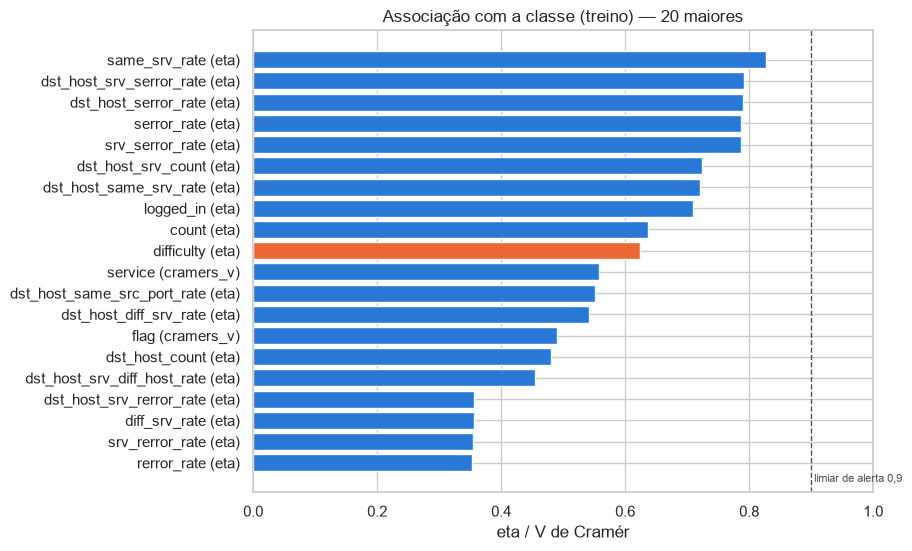

In [22]:
plot = assoc.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#eb6834" if a in config.LEAKY_COLUMNS else "#2a78d6" for a in plot["atributo"]]
ax.barh(plot["atributo"] + " (" + plot["medida"] + ")", plot["associacao"], color=colors)
ax.axvline(0.9, color="#52514e", ls="--", lw=1)
ax.text(0.9, -0.9, " limiar de alerta 0,9", fontsize=8, color="#52514e")
ax.set(title="Associação com a classe (treino) — 20 maiores", xlabel="eta / V de Cramér",
       xlim=(0, 1))
savefig(fig, "associacao_classe")
plt.show()

,mean,50%,min,max
category,,,,
normal,20.32,21.0,1.0,21.0
DoS,19.31,20.0,3.0,21.0
Probe,16.46,17.0,0.0,21.0
R2L,9.88,11.0,0.0,19.0
U2R,4.40,3.0,0.0,14.0


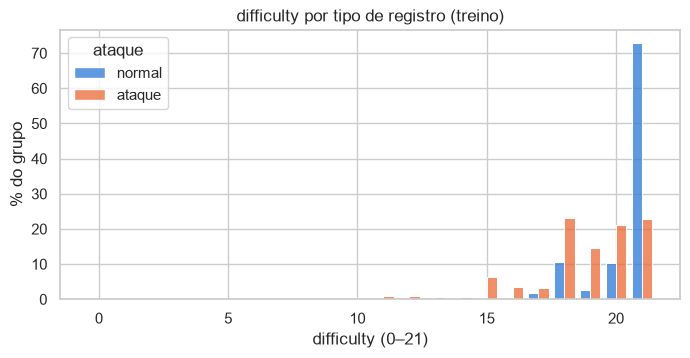

In [23]:
dif = df.assign(ataque=np.where(df["category"] == "normal", "normal", "ataque"))
display(dif.groupby("category")["difficulty"].describe()[["mean", "50%", "min", "max"]]
        .reindex(CLASSES).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=dif, x="difficulty", hue="ataque", discrete=True, stat="percent",
             common_norm=False, palette={"normal": "#2a78d6", "ataque": "#eb6834"}, ax=ax,
             multiple="dodge", shrink=0.8)
ax.set(title="difficulty por tipo de registro (treino)", xlabel="difficulty (0–21)",
       ylabel="% do grupo")
savefig(fig, "difficulty")
plt.show()

**Conclusões da investigação de vazamento**

1. **`difficulty` será descartado.** Ele não é uma medida do tráfego: segundo os autores do
   NSL-KDD, é o número de classificadores de referência (de 21) que acertaram aquele registro,
   ou seja, é **derivado do rótulo e do processo de rotulagem** e não existe para uma conexão
   nova. Sua distribuição muda fortemente com a classe (média 20,3 em `normal`, 9,9 em `R2L` e
   4,4 em `U2R`; eta = 0,62, 10º lugar na tabela): é exatamente o tipo de informação que diz
   "este registro é difícil, logo provavelmente é um ataque raro". Usá-lo inflaria o desempenho
   de forma ilegítima. Note que o critério aqui é **semântico** (origem do atributo), não o
   valor numérico da associação, que nem chega ao limiar. O carregador `load_train()` já o
   exclui de `X`.
2. **Nenhum dos 41 atributos é substituto do rótulo.** Nenhum atinge o limiar de alerta
   (0,9); o maior é `same_srv_rate` (eta = 0,83). Os mais associados (taxas de erro SYN,
   `dst_host_srv_count`, `logged_in`, `count`, `service`, `flag`) têm associação alta por razões
   legítimas — descrevem o comportamento do tráfego que define DoS e Probe — e serão mantidos.
3. `attack` (nome do ataque) é o rótulo fino: usado apenas para gerar `category` e como grupo em
   uma validação cruzada diagnóstica, nunca como atributo.
4. Vazamento metodológico (ajuste de codificador, escala, seleção ou balanceamento fora dos
   folds) será evitado colocando todos esses passos dentro de um único `Pipeline` avaliado por
   validação cruzada no treino (Etapas 2 e 3).

## 10. Comparação descritiva treino × teste (somente rótulos)

**Única exceção ao isolamento do teste, e por quê.** Lemos do KDDTest+ **apenas as colunas de
rótulo** (`attack` e `category`), para documentar a mudança de distribuição entre os conjuntos.
Nenhum atributo do teste é examinado e nenhuma decisão de pré-processamento ou modelagem é
tomada com base nesta seção — ela só explica por que a validação cruzada no treino tende a ser
otimista. O teste não é usado de nenhuma outra forma até o notebook 04.

In [24]:
from nslkdd.data import load_test_frame

test_labels = load_test_frame(final_evaluation=True)[["attack", "category"]]

comp = pd.DataFrame({"treino": df["category"].value_counts(),
                     "teste": test_labels["category"].value_counts()}).reindex(CLASSES)
comp["% treino"] = (100 * comp["treino"] / comp["treino"].sum()).round(2)
comp["% teste"] = (100 * comp["teste"] / comp["teste"].sum()).round(2)
comp.loc["total"] = comp.sum().round(2)
comp

,treino,teste,% treino,% teste
category,,,,
normal,67343.0,9711.0,53.46,43.08
DoS,45927.0,7458.0,36.46,33.08
Probe,11656.0,2421.0,9.25,10.74
R2L,995.0,2754.0,0.79,12.22
U2R,52.0,200.0,0.04,0.89
total,125973.0,22544.0,100.00,100.01


In [25]:
new_attacks = sorted(set(test_labels["attack"]) - set(df["attack"]))
only_train = sorted(set(df["attack"]) - set(test_labels["attack"]))
new_cnt = test_labels[test_labels["attack"].isin(new_attacks)]
print(f"{len(new_attacks)} ataques só no teste ({len(new_cnt)} registros):")
print(new_cnt.groupby("category")["attack"].value_counts().to_string())
print("\nataques só no treino:", only_train)
share = (new_cnt["category"].value_counts() / test_labels["category"].value_counts()).reindex(CLASSES)
print("\n% de cada classe do teste formada por ataques inéditos:")
print((100 * share).round(1).fillna(0).to_string())

17 ataques só no teste (3750 registros):
category  attack       
DoS       apache2          737
          processtable     685
          mailbomb         293
          udpstorm           2
Probe     mscan            996
          saint            319
R2L       snmpguess        331
          snmpgetattack    178
          named             17
          sendmail          14
          xlock              9
          xsnoop             4
          worm               2
U2R       httptunnel       133
          ps                15
          xterm             13
          sqlattack          2

ataques só no treino: ['spy', 'warezclient']

% de cada classe do teste formada por ataques inéditos:
category
normal     0.0
DoS       23.0
Probe     54.3
R2L       20.2
U2R       81.5


In [26]:
for c in ["R2L", "U2R"]:
    tr = df.loc[df["category"] == c, "attack"].value_counts()
    te = test_labels.loc[test_labels["category"] == c, "attack"].value_counts()
    print(f"\n{c}:\n", pd.DataFrame({"treino": tr, "teste": te}).fillna(0).astype(int)
          .sort_values("teste", ascending=False).to_string())


R2L:
                treino  teste
attack                      
guess_passwd       53   1231
warezmaster        20    944
snmpguess           0    331
snmpgetattack       0    178
multihop            7     18
named               0     17
sendmail            0     14
xlock               0      9
xsnoop              0      4
ftp_write           8      3
phf                 4      2
worm                0      2
imap               11      1
warezclient       890      0
spy                 2      0

U2R:
                  treino  teste
attack                        
httptunnel            0    133
buffer_overflow      30     20
ps                    0     15
rootkit              10     13
xterm                 0     13
loadmodule            9      2
perl                  3      2
sqlattack             0      2


A distribuição muda bastante:
- `R2L` passa de **995 (0,8%) para 2.754 (12,2%)** e `U2R` de **52 (0,04%) para 200 (0,9%)**;
- **17 ataques aparecem só no teste** (p.ex. `mscan`, `apache2`, `snmpguess`, `httptunnel`);
  eles formam 81,5% do `U2R` e 54,3% do `Probe` do teste (`httptunnel` sozinho são 133 dos
  200 `U2R`);
- o `R2L` do treino é quase todo `warezclient`, que não existe no teste, enquanto o `R2L` do
  teste é dominado por `guess_passwd` e `warezmaster`, que no treino têm só 53 e 20 exemplos.

**Implicação:** uma validação cruzada estratificada no treino mede a capacidade de reconhecer
ataques *já vistos*, e por isso será otimista em relação ao KDDTest+. Na Etapa 3 usaremos, além
da CV estratificada, uma **CV agrupada por tipo de ataque** (cada ataque inteiro num único fold),
que simula ataques inéditos usando somente o treino. Isso favorece escolhas que generalizam
(modelos menos sobreajustados, balanceamento que aumenta o recall de R2L/U2R).

## 11. Diagnóstico e plano para a Etapa 2

| Problema | Evidência (treino) | Técnica(s) a comparar na Etapa 2 | Por quê |
|---|---|---|---|
| Desbalanceamento extremo | U2R 0,04% (52), R2L 0,8% (995); razão 1.295:1 | SMOTE, sobreamostragem aleatória (ROS), subamostragem aleatória (RUS), híbrido, `class_weight` | F1-macro pesa igualmente as classes raras |
| Acurácia enganosa | "tudo normal" = 53,5% de acurácia, F1-macro 0,14 | seleção de modelos só por F1-macro de CV | métrica oficial |
| `service` com 70 categorias | cauda longa, 15 categorias < 0,1% | one-hot vs one-hot com raras agrupadas vs frequência vs target encoding | alta cardinalidade; R2L/U2R dependem do serviço |
| `protocol_type`, `flag` categóricos | 3 e 11 valores, muito discriminantes | one-hot | baixa cardinalidade, sem ordem |
| Cauda longa / escalas distintas | skew de `src_bytes` ≈ 190, máx. 1,38 bi | `log1p` + Standard / MinMax / Robust | KNN e MLP sensíveis à escala |
| Outliers | concentrados em R2L/U2R | **não** eliminar globalmente; `log1p` + escala robusta | outliers são o sinal das classes raras |
| Atributo constante | `num_outbound_cmds` = 0 | remover | sem informação |
| Valor fora do domínio | `su_attempted` = 2 (59 linhas) | tratar como contagem ou binarizar (> 0) | preserva a informação |
| Atributos redundantes | 10 pares com \|r\| > 0,95 | seleção (SelectKBest / importância de árvores) ou PCA | redundância prejudica KNN/NB |
| Instâncias inconsistentes | 15 grupos (31 linhas) com rótulos diferentes | manter / remover duplicatas / remover inconsistentes / rótulo majoritário | exigência 1 do enunciado |
| Vazamento | `difficulty` derivado da rotulagem | descartar | indisponível em produção |
| Mudança de distribuição | 17 ataques inéditos; proporção de R2L ×15 | CV agrupada por ataque como diagnóstico | CV estratificada será otimista |

Todos os passos que aprendem algo dos dados (codificação, escala, seleção/PCA, balanceamento e
tratamento de redundância) serão colocados **dentro do pipeline** e ajustados apenas nos folds
de treino da validação cruzada.

### Auditoria de vazamento deste notebook

`python -m nslkdd.audit notebooks/01_eda.ipynb` retorna **0 erros** e alertas esperados:
- menções a `'difficulty'` (Seções 8 e 9): o atributo é *analisado* para justificar o seu
  descarte; ele não entra em nenhum `X`;
- `load_test_frame(final_evaluation=True)` (Seção 10): leitura apenas das colunas de rótulo do
  teste, de forma descritiva e justificada no início da seção.